In [35]:
import pandas as pd
import numpy as np

In [36]:
df = pd.read_excel('final_customer_data.xlsx')


In [37]:
display(df.head())
print("\n--- Informasi Awal Dataset ---")
df.info()

,User_id,Session_id,DateTime,Category,SubCategory,Action,Quantity,Rate,Total Price
0,52243841613,d76fde-8bb3-4e00-8c23,2019-01-10 10:20:00,Electronic Appliances,Speakers,first_app_open,NaN,NaN,NaN
1,52243841613,33dfbd-b87a-4708-9857,2019-01-10 10:22:00,Electronic Appliances,Speakers,search,NaN,NaN,NaN
2,57314161118,6511c2-e2e3-422b-b695,2019-01-10 14:00:00,Men's Fashion,Jeans,search,NaN,NaN,NaN
3,57314161118,90fc70-0e80-4590-96f3,2019-01-10 14:07:00,Men's Fashion,Jeans,product_view,NaN,NaN,NaN
4,57314161118,bd7419-2748-4c56-95b4,2019-01-10 14:12:00,Men's Fashion,Jeans,read_reviews,NaN,NaN,NaN



--- Informasi Awal Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2090 entries, 0 to 2089
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   User_id      2090 non-null   int64  
 1   Session_id   2090 non-null   object 
 2   DateTime     2090 non-null   object 
 3   Category     2090 non-null   object 
 4   SubCategory  2090 non-null   object 
 5   Action       2090 non-null   object 
 6   Quantity     201 non-null    float64
 7   Rate         201 non-null    float64
 8   Total Price  201 non-null    float64
dtypes: float64(3), int64(1), object(5)
memory usage: 147.1+ KB


In [38]:
print("--- Jumlah Missing Values Sebelum Dibersihkan ---")
print(df.isnull().sum())

--- Jumlah Missing Values Sebelum Dibersihkan ---
User_id           0
Session_id        0
DateTime          0
Category          0
SubCategory       0
Action            0
Quantity       1889
Rate           1889
Total Price    1889
dtype: int64


In [39]:
df['Quantity'] = df['Quantity'].fillna(0).astype(int)
df['Rate'] = df['Rate'].fillna(0).astype(float)
df['Total Price'] = df['Total Price'].fillna(0).astype(float)

print("\n--- Jumlah Missing Values Setelah Dibersihkan ---")
print(df.isnull().sum())



--- Jumlah Missing Values Setelah Dibersihkan ---
User_id        0
Session_id     0
DateTime       0
Category       0
SubCategory    0
Action         0
Quantity       0
Rate           0
Total Price    0
dtype: int64


In [40]:
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

Jumlah baris duplikat: 0


In [41]:
df['Category'] = df['Category'].astype(str).str.strip().str.title()
df['SubCategory'] = df['SubCategory'].astype(str).str.strip().str.title()
df['Action'] = df['Action'].astype(str).str.strip().str.lower()

In [42]:
perbaikan_action = {
    'add_to_wishist': 'add_to_wishlist',  # typo kurang huruf 'l' (5 baris)
    'read_review': 'read_reviews',        # menyamakan bentuk tunggal ke jamak (1 baris)
    'product_review': 'read_reviews'      # menyamakan istilah baca ulasan produk (22 baris)
}
df['Action'] = df['Action'].replace(perbaikan_action)

print("\n--- Distribusi Action Setelah Dirapikan ---")
print(df['Action'].value_counts())
print("\nJumlah Kategori unik setelah dirapikan:", df['Category'].nunique())


--- Distribusi Action Setelah Dirapikan ---
Action
read_reviews           365
search                 320
product_view           292
add_to_cart            280
click_wishlist_page    202
checkout               202
purchase               201
first_app_open         121
add_review              69
add_to_wishlist         38
Name: count, dtype: int64

Jumlah Kategori unik setelah dirapikan: 102


In [43]:
df['User_id'] = df['User_id'].astype(str)
df['DateTime'] = pd.to_datetime(df['DateTime'], format='mixed', dayfirst=True)


In [44]:
df_purchase = df[df['Action'] == 'purchase']

Q1 = df_purchase['Total Price'].quantile(0.25)
Q3 = df_purchase['Total Price'].quantile(0.75)
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR

outliers = df_purchase[df_purchase['Total Price'] > batas_atas]

print(f"Q1 (25%): {Q1:,.0f} | Q3 (75%): {Q3:,.0f} | IQR: {IQR:,.0f}")
print(f"Batas Atas Outlier (Q3 + 1.5*IQR): {batas_atas:,.0f}")
print(f"Jumlah Transaksi Outlier: {len(outliers)} dari {len(df_purchase)} transaksi pembelian\n")


Q1 (25%): 1,000 | Q3 (75%): 8,000 | IQR: 7,000
Batas Atas Outlier (Q3 + 1.5*IQR): 18,500
Jumlah Transaksi Outlier: 29 dari 201 transaksi pembelian



In [45]:
# Menampilkan contoh transaksi outlier
display(outliers[['User_id', 'Category', 'SubCategory', 'Quantity', 'Rate', 'Total Price']].head(10))

,User_id,Category,SubCategory,Quantity,Rate,Total Price
85,51613167885,Mobile & Accessories,Mobile,3,20000.0,60000.0
106,51795247161,Digital Devices,Tws Earbuds,2,15000.0,30000.0
166,51945183373,Digital Devices,Printers,1,30000.0,30000.0
480,51626168971,Digital Devices,Laptop,1,45000.0,45000.0
492,51970999139,Camera Accessories,Tripods,2,12000.0,24000.0
509,51472029210,Entertainment Systems,Surround System,2,12200.0,24400.0
545,51526464449,Digital Appliances,Laptop,1,50000.0,50000.0
566,51895612143,Large Appliances,Washing Machine,1,50000.0,50000.0
569,52112239597,Furnitures,Sofa,1,40000.0,40000.0
610,51978529551,Music,Amplifier,1,25000.0,25000.0


In [46]:
# Penanganan Outlier:
# Transaksi di atas 18.500 (seperti Gaming Laptop 90.000, TV 85.000, iPad 160.000) adalah
# transaksi produk elektronik asli (bukan salah input). Oleh karena itu, data TIDAK dihapus
# agar perhitungan total pendapatan tetap akurat, melainkan diberi kolom penanda (flag).
df['Is_High_Value_Order'] = np.where(df['Total Price'] > batas_atas, 'High Value (Outlier)', 'Normal')

# EDA


In [47]:
# 2.1 Membuat variabel waktu baru dari kolom DateTime
df['Date'] = df['DateTime'].dt.date
df['Month'] = df['DateTime'].dt.month_name()
df['DayOfWeek'] = df['DateTime'].dt.day_name()
df['Hour'] = df['DateTime'].dt.hour

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Filter khusus transaksi sukses (purchase) untuk analisis finansial
df_purchase = df[df['Action'] == 'purchase'].copy()

print(f"Total seluruh baris data: {len(df)}")
print(f"Total transaksi sukses (purchase): {len(df_purchase)}")

Total seluruh baris data: 2090
Total transaksi sukses (purchase): 201


In [49]:
print("--- STATISTIK DESKRIPTIF NILAI TRANSAKSI (TOTAL PRICE) ---")
print(df_purchase['Total Price'].describe())

print("\nMedian (Nilai Tengah) Total Price:", df_purchase['Total Price'].median())

--- STATISTIK DESKRIPTIF NILAI TRANSAKSI (TOTAL PRICE) ---
count       201.000000
mean       9455.373134
std       18213.695424
min         150.000000
25%        1000.000000
50%        2500.000000
75%        8000.000000
max      160000.000000
Name: Total Price, dtype: float64

Median (Nilai Tengah) Total Price: 2500.0


--- TOP 5 KATEGORI PRODUK BERDASARKAN PENDAPATAN ---
Category
Tablets                 225000.0
Mobile & Accessories    127000.0
Digital Devices         121800.0
Women'S Fashion         103450.0
Laptop And Desktop       90000.0
Name: Total Price, dtype: float64


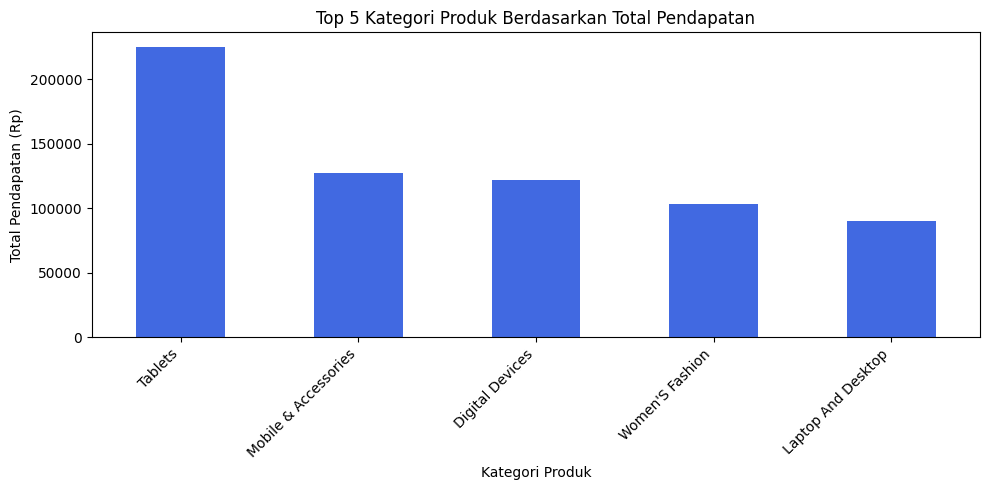

In [50]:
#Analisis Kategori Produk dengan Pendapatan Tertinggi (Top Revenue Category)
# Agregasi total pendapatan per kategori
top_category_revenue = df_purchase.groupby('Category')['Total Price'].sum().sort_values(ascending=False).head(5)

print("--- TOP 5 KATEGORI PRODUK BERDASARKAN PENDAPATAN ---")
print(top_category_revenue)

# Visualisasi Bar Chart
plt.figure(figsize=(10, 5))
top_category_revenue.plot(kind='bar', color='royalblue')
plt.title('Top 5 Kategori Produk Berdasarkan Total Pendapatan')
plt.xlabel('Kategori Produk')
plt.ylabel('Total Pendapatan (Rp)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

--- TOTAL PENDAPATAN BERDASARKAN JAM TRANSAKSI ---
Hour
8       1200.0
10    116150.0
11     69750.0
12     30700.0
13    103300.0
14    232250.0
15    412950.0
16     24850.0
17    112450.0
18    107570.0
Name: Total Price, dtype: float64


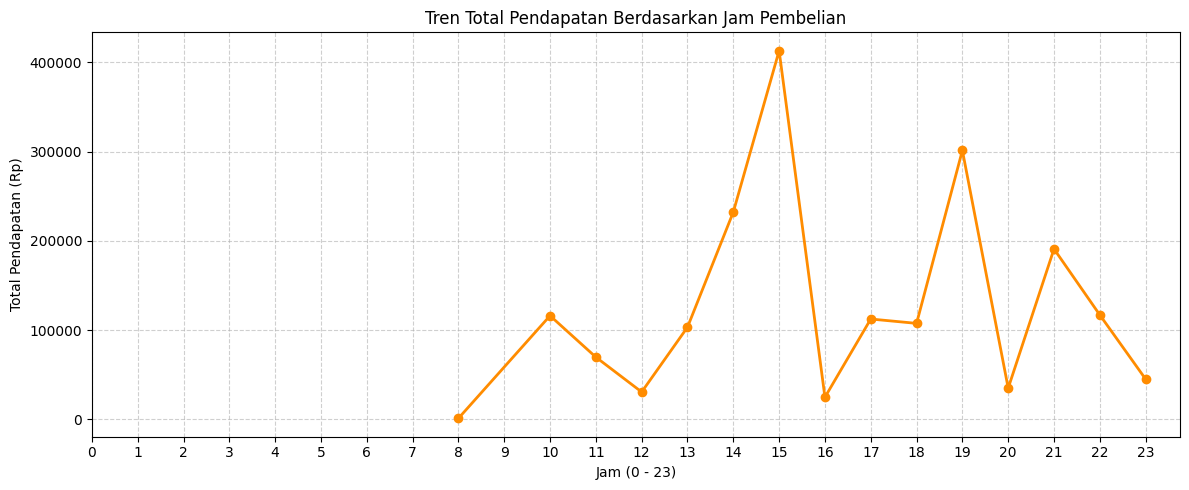

In [51]:
# Ekstraksi jam dari DateTime jika belum ada
df['Hour'] = pd.to_datetime(df['DateTime']).dt.hour

# Filter jam pada data purchase
hourly_purchase = df[df['Action'] == 'purchase'].groupby('Hour')['Total Price'].sum()

print("--- TOTAL PENDAPATAN BERDASARKAN JAM TRANSAKSI ---")
print(hourly_purchase.head(10))

# Visualisasi Line Chart
plt.figure(figsize=(12, 5))
hourly_purchase.plot(kind='line', marker='o', color='darkorange', linewidth=2)
plt.title('Tren Total Pendapatan Berdasarkan Jam Pembelian')
plt.xlabel('Jam (0 - 23)')
plt.ylabel('Total Pendapatan (Rp)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

In [52]:
output_file = 'cleaned_customer_data.xlsx'
df.to_excel(output_file, index=False)

print(f"Data bersih berhasil di-export ke file: {output_file}")

Data bersih berhasil di-export ke file: cleaned_customer_data.xlsx
